# Simulate NG15-like data with a continuous wave and recover it

We'll load the NANOGrav 15 year dataset, inject our own red noise, gravitational
wave background and a continuous wave from a single supermassive black hole
binary, and perform parameter estimation with Prometheus.

Without the wave: [`ng15_stochastic_pe.ipynb`](ng15_stochastic_pe.ipynb).

In [16]:
import numpy as np
import pickle
import json
import matplotlib.pyplot as plt
import corner
import healpy as hp

import jax.random as jr
import numpyro

from enterprise_extensions.load_feathers import load_feathers_from_folder

import pta_sims
from prometheus import data
from prometheus.spectral_models import IndependentSpectralModel, CommonSpectralModel
from prometheus.deterministic_models import DeterministicModel
from prometheus import spectra, deterministic
from prometheus.pta_model import PTAModel

## Load data

In [17]:
# # load feather pulsar objects
# psrs = load_feathers_from_folder('../data/NG15/feathers')

# # load white noise dictionary
# with open('../data/NG15/15yr_wn_dict.json', 'r') as fp:
#     wn_dict = json.load(fp)

# # pulsar distances: the CW pulsar term needs them
# with open('../data/NG15/pulsar_distances_15yr.pkl', 'rb') as fp:
#     psr_dists_dict = pickle.load(fp)

In [18]:
# # now we can construct the prometheus.data.Data object
# dataset = data.Data(name='NG15',
#                     psrs=psrs,
#                     wn_dict=wn_dict,
#                     nfreqs=30,
#                     psr_dists_dict=psr_dists_dict)

In [ ]:
# save the data object for future analyses
# dataset.save_data(filepath='../data/NG15/data.pkl')

# or load a previously constructed data object
with open('../data/NG15/data.pkl', 'rb') as fp:
    dataset = pickle.load(fp)

## Inject GWB, IRN & CW

In [5]:
# simulation model: a power law per pulsar, a Hellings-Downs correlated
# background, and a continuous wave on top.
model = pta_sims.build_standard_model(
    dataset, correlations='HD', det_model=pta_sims.build_cw_model(dataset))

# cw injection
cw = pta_sims.cw_params(log10_mc=9.5, log10_fgw=np.log10(4e-9), cos_inc=0.6,
                        psi=0.9, log10_h=-14.30, cos_gwtheta=0.043,
                        gwphi=4.06, phase0=1.2)

# The CW phase at each pulsar from the source and that pulsar's distance
psr_phases = pta_sims.cw_psr_phases(dataset, cw)

# injected parameters
rng = np.random.default_rng(42)
params = {'red_noise':  pta_sims.power_law_params(
                            rng.normal(-15.5, 0.3, dataset.npsrs),
                            rng.normal(2.5, 0.4, dataset.npsrs),
                            npsrs=dataset.npsrs),
          'gwb':        pta_sims.power_law_params(-14.6, 13 / 3),
          'cw':         cw,
          'psr_phases': psr_phases}

# simulate data
simulated_dataset = pta_sims.simulate(model, params, seed=42)
print(simulated_dataset.summary())

print(f"\nmatched-filter SNR {simulated_dataset.truth['snr']:.2f} "
      f"(white noise only), "
      f"{simulated_dataset.truth['snr_marginalized']:.2f} "
      f"(red noise and background marginalized)")

Simulated dataset "NG15_sim"
  pulsars 67, stochastic components 60, deterministic components 120
  white noise included: True
  joint Gram rank 18-63 of 180 (truncation rtol 1e-12)
  largest negative-eigenvalue fraction 8.02e-14  (float64 rounding floor ~1e-15; >1e-13 means the stored Gram matrix is itself no longer numerically PSD)
  trace discarded by truncation 1.10e-12
  deterministic SNR 61.48 (white noise only), 5.93 (stochastic processes marginalized)
  float32 downcast into Data:
    FNrs     max rel err 5.80e-08, 0 non-finite, 0 underflowed to zero (range 1.12e-08 .. 9.73e+00)
    FNFs     max rel err 5.96e-08, 0 non-finite, 0 underflowed to zero (range 3.04e-14 .. 2.96e-02)
    TDNrs    max rel err 5.88e-08, 0 non-finite, 0 underflowed to zero (range 5.48e-10 .. 9.79e+00)
    TNTDs    max rel err 5.96e-08, 0 non-finite, 0 underflowed to zero (range 5.14e-17 .. 2.90e-02)
    TDNTDs   max rel err 5.96e-08, 0 non-finite, 0 underflowed to zero (range 2.59e-18 .. 2.96e-02)

match

## Recovery models

In [ ]:
# pulsar intrinsic noise model
psr_model = IndependentSpectralModel(name='psr_params',
                                     get_phi_diag_func=spectra.power_law,
                                     parameter_bounds=[[-20., -10.],
                                                       [0., 7.]],
                                     data=simulated_dataset.data)

# background model
gwb_model = CommonSpectralModel(name='gwb_params',
                                get_phi_diag_func=spectra.power_law,
                                parameter_bounds=[[-20., -10.],
                                                    [0., 7.]],
                                correlation_matrix='HD',
                                data=simulated_dataset.data)

# continuous wave model
cw_model = DeterministicModel(name='cw_params',
                              get_delays_func=deterministic.cw_delay_full_prior_float32,
                              parameter_bounds=pta_sims.models.DEFAULT_CW_BOUNDS,
                              with_psr_params=True,
                              data=simulated_dataset.data)

# joint PTA model
pta_model = PTAModel(psr_model=psr_model, gwb_model=gwb_model,
                     det_model=cw_model)

In [7]:
# NUTS
nuts_kernel = numpyro.infer.NUTS(model=pta_model.sampling_model)
mcmc = numpyro.infer.MCMC(sampler=nuts_kernel,
                          num_warmup=1000,
                          num_samples=4000)
mcmc.run(jr.key(1234))
samples = mcmc.get_samples()

sample: 100%|██████████| 5000/5000 [27:09<00:00,  3.07it/s, 255 steps of size 1.49e-02. acc. prob=0.80]  


## Plot recovery

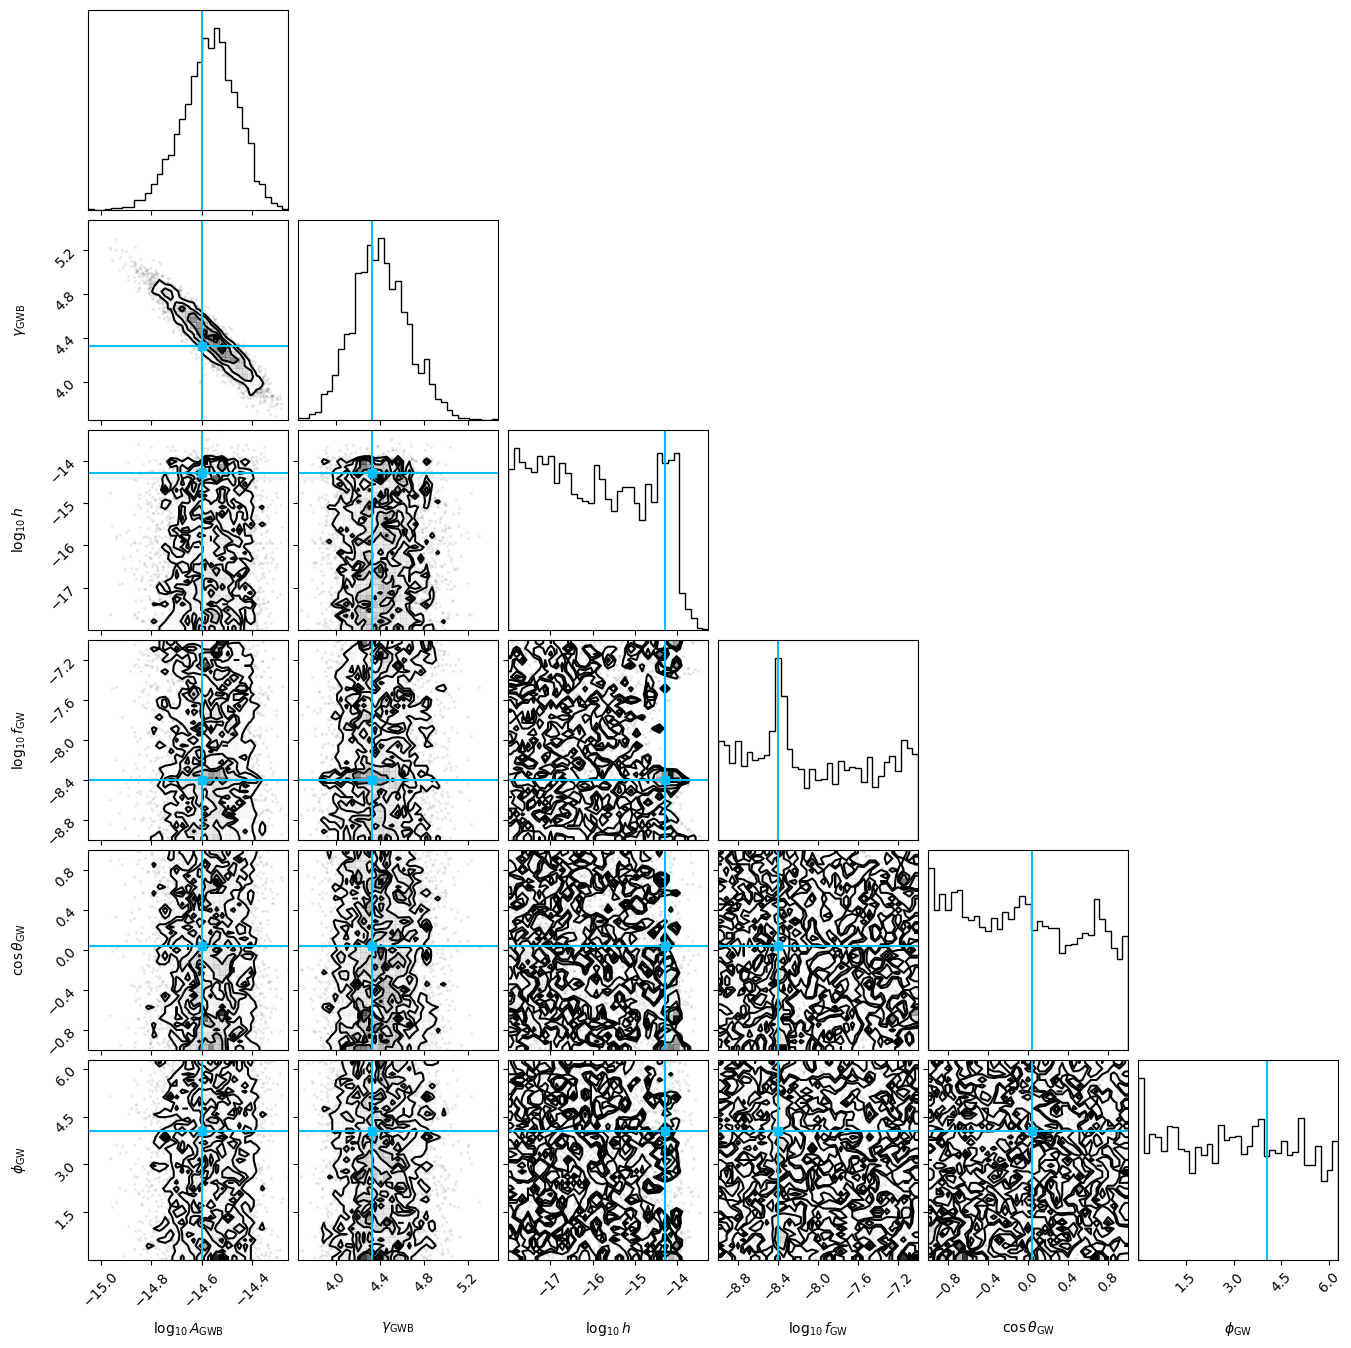

In [ ]:
# GWB + CW recovery
cw_chain = np.array(samples['cw_params'])
fig = corner.corner(
    np.column_stack([np.array(samples['gwb_params']), cw_chain[:, [4, 1, 5, 6]]]),
    bins=35,
    truths=list(params['gwb']) + [cw[k] for k in (4, 1, 5, 6)],
    labels=[r'$\log_{10}A_\text{GWB}$', r'$\gamma_\text{GWB}$',
            r'$\log_{10}h$', r'$\log_{10}f_\text{GW}$',
            r'$\cos\theta_\text{GW}$', r'$\phi_\text{GW}$'],
    truth_color='deepskyblue')